In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [3]:
df=pd.read_csv('Titanic.csv')
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [11]:
features_of_interest=['Survived','Age','Sex','Pclass','Fare','Embarked']
display(df[features_of_interest].head())

,Survived,Age,Sex,Pclass,Fare,Embarked
0,0,22.0,male,3,7.2500,S
1,1,38.0,female,1,71.2833,C
2,1,26.0,female,3,7.9250,S
3,1,35.0,female,1,53.1000,S
4,0,35.0,male,3,8.0500,S


In [13]:
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

In [42]:
df=df.ffill()

In [45]:
df.isnull().sum()

PassengerId          0
Survived             0
Pclass               0
Name                 0
Sex                891
Age                  0
SibSp                0
Parch                0
Ticket               0
Fare                 0
Cabin                1
Embarked_S           0
Embarked_Q_True      0
dtype: int64

In [30]:
print(df.columns.str.strip())

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked_S', 'Embarked_Q_True'],
      dtype='str')


C:\Users\User\AppData\Local\Temp\ipykernel_18860\3505939269.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.barplot(data=df,x='Sex',y='Survived',hue='Sex',palette='Blues',legend=False)


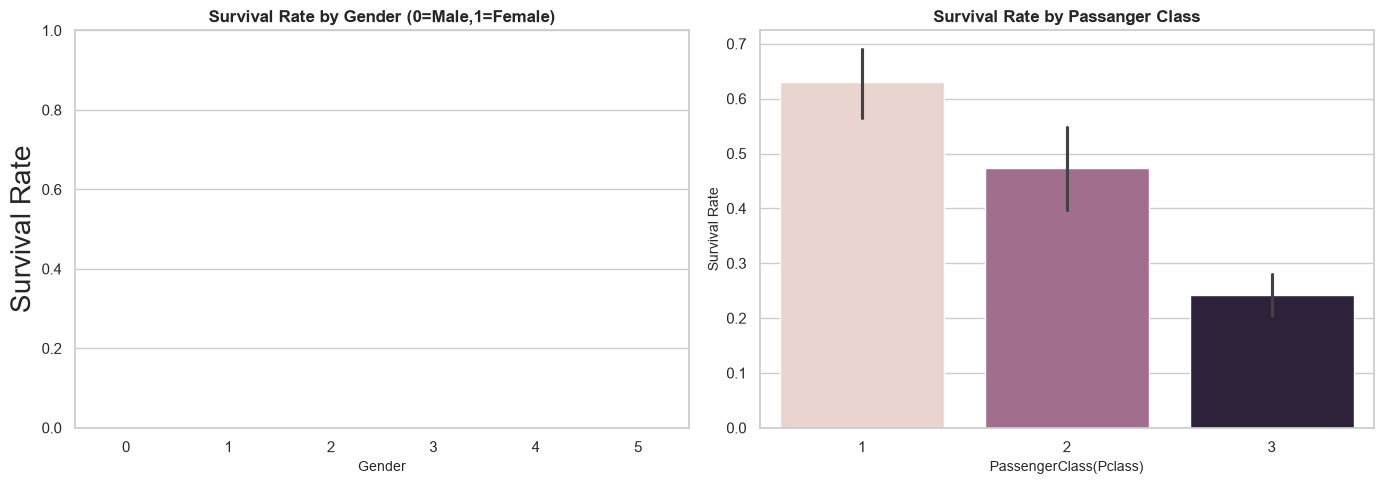

In [33]:
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
sns.barplot(data=df,x='Sex',y='Survived',hue='Sex',palette='Blues',legend=False)
plt.title('Survival Rate by Gender (0=Male,1=Female)',fontsize=12,fontweight='bold')
plt.ylabel('Survival Rate',fontsize=20)
plt.xlabel('Gender',fontsize=10)
plt.subplot(1,2,2)
sns.barplot(data=df,x='Pclass',y='Survived',hue='Pclass',legend=False)
plt.title('Survival Rate by Passanger Class',fontsize=12,fontweight='bold')
plt.xlabel('PassengerClass(Pclass)',fontsize=10)
plt.ylabel('Survival Rate',fontsize=10)
plt.tight_layout()
plt.show()

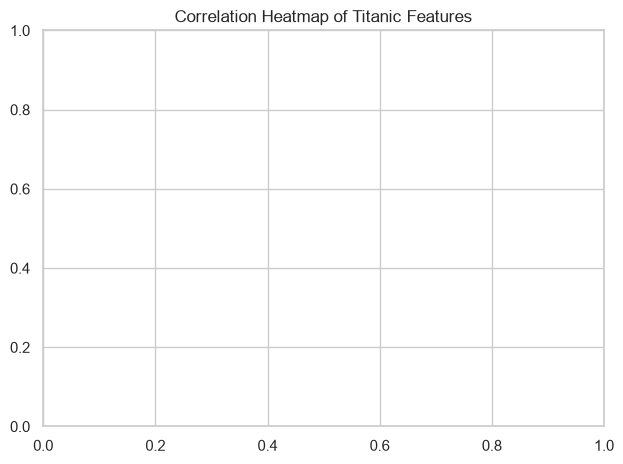

In [35]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
plt.title('Correlation Heatmap of Titanic Features')
plt.tight_layout()
plt.show()

In [49]:
df=df.fillna(0)

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
X=df.drop(columns=['Survived','Name','Ticket','Cabin'],errors='ignore')
Y=df['Survived']
X_train, X_test, Y_train, Y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
log_reg=LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train,Y_train)
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(X_train,Y_train)
print("Models trained successfully!")


Models trained successfully!


In [55]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("--- Logistic Regression Evaluation ")
Y_pred_lr = log_reg.predict(X_test)
print(f"Accuracy: {accuracy_score(Y_test, Y_pred_lr):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred_lr))
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred_lr))

print("\n" + "="*50 + "\n")

print("--- Random Forest Classifier Evaluation ---")
y_pred_rf = rf_model.predict(X_test)
print(f"Accuracy: {accuracy_score(Y_test, Y_pred_rf):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred_rf))
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred_rf))

--- Logistic Regression Evaluation 
Accuracy: 0.7207

Confusion Matrix:
[[92 13]
 [37 37]]

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.88      0.79       105
           1       0.74      0.50      0.60        74

    accuracy                           0.72       179
   macro avg       0.73      0.69      0.69       179
weighted avg       0.72      0.72      0.71       179



--- Random Forest Classifier Evaluation ---


NameError: name 'Y_pred_rf' is not defined

NameError: name 'Y_pred_rf' is not defined

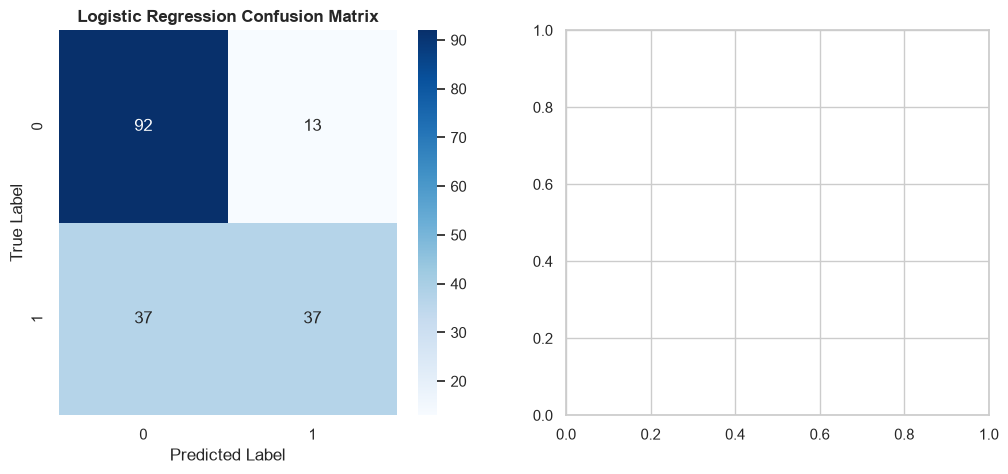

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(Y_test, Y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix', fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(confusion_matrix(Y_test, Y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()